# 01 - Exploration des données

Objectif : regarder les données brutes **avant** de modéliser. On vérifie combien d'images
contient chaque classe, leurs formats de fichier, leurs tailles et leurs modes de couleur,
puis on affiche quelques exemples.

Jeu de données : *Brain Tumor MRI Dataset* (Masoud Nickparvar, Kaggle, licence CC BY 4.0).
Il faut d'abord le télécharger avec `uv run python scripts/download_data.py`.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

RAW_DIR = Path("../../data/raw")  # chemin relatif à ml/notebooks/
SPLITS = ["Training", "Testing"]  # les deux dossiers du jeu de données

print("Contenu de data/raw :", sorted(p.name for p in RAW_DIR.iterdir()))

Contenu de data/raw : ['Testing', 'Training']


## 1. Une ligne par image
On lit seulement l'en-tête de chaque fichier (rapide), pas les pixels.

In [2]:
rows = []
for split in SPLITS:
    for class_dir in sorted((RAW_DIR / split).iterdir()):  # un dossier par classe
        for path in sorted(class_dir.iterdir()):
            with Image.open(path) as img:
                rows.append(
                    {
                        "split": split,
                        "label": class_dir.name,
                        "path": path,
                        "suffix": path.suffix.lower(),
                        "mode": img.mode,
                        "width": img.width,
                        "height": img.height,
                    }
                )
df = pd.DataFrame(rows)
print(df.shape)  # (nombre d'images, nombre de colonnes)
df.head()

(7200, 7)


,split,label,path,suffix,mode,width,height
0,Training,glioma,..\..\data\raw\Training\glioma\Tr-gl_1.jpg,.jpg,L,512,512
1,Training,glioma,..\..\data\raw\Training\glioma\Tr-gl_10.jpg,.jpg,L,512,512
2,Training,glioma,..\..\data\raw\Training\glioma\Tr-gl_100.jpg,.jpg,L,512,512
3,Training,glioma,..\..\data\raw\Training\glioma\Tr-gl_1000.jpg,.jpg,L,512,512
4,Training,glioma,..\..\data\raw\Training\glioma\Tr-gl_1001.jpg,.jpg,L,512,512


## 2. Images par classe et par jeu

label     glioma  meningioma  notumor  pituitary  total
split                                                  
Testing      400         400      400        400   1600
Training    1400        1400     1400       1400   5600


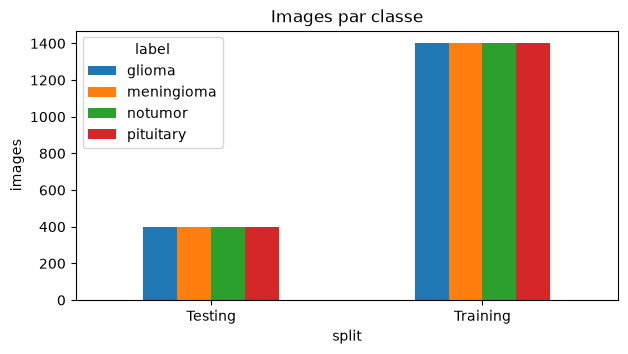

In [3]:
counts = df.groupby(["split", "label"]).size().unstack("label")
counts["total"] = counts.sum(axis=1)
print(counts)
counts.drop(columns="total").plot(kind="bar", figsize=(7, 3.5), title="Images par classe")
plt.ylabel("images")
plt.xticks(rotation=0)
plt.show()

## 3. Formats de fichier et modes de couleur
Un modèle attend 3 canaux (RGB). Les images en niveaux de gris (`L`) devront être converties.

In [4]:
print("Extensions de fichier :", dict(Counter(df["suffix"])))
print("Modes de couleur      :", dict(Counter(df["mode"])))
print()
print(df.groupby(["split", "mode"]).size().unstack(fill_value=0))

Extensions de fichier : {'.jpg': 7200}
Modes de couleur      : {'L': 3067, 'RGB': 4129, 'RGBA': 3, 'P': 1}

mode         L  P   RGB  RGBA
split                        
Testing    709  0   891     0
Training  2358  1  3238     3


## 4. Tailles des images
Les images ont des tailles différentes : il faut toutes les redimensionner à la même taille (224 x 224 pour ResNet-50).

Tailles distinctes : 447
Les plus fréquentes : [((512, 512), 5014), ((225, 225), 338), ((630, 630), 90), ((201, 251), 57), ((228, 221), 51)]
      width  height
min   150.0   167.0
50%   512.0   512.0
max  1375.0  1446.0


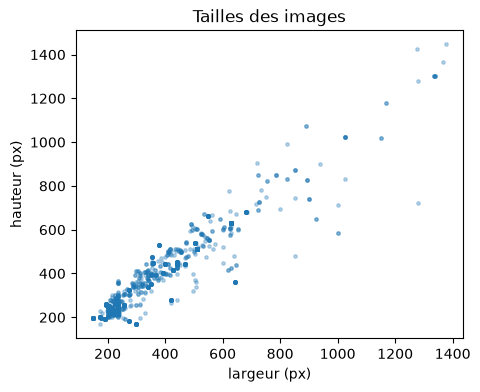

In [5]:
sizes = Counter(zip(df["width"], df["height"], strict=True))
print("Tailles distinctes :", len(sizes))
print("Les plus fréquentes :", sizes.most_common(5))
print(df[["width", "height"]].describe().loc[["min", "50%", "max"]])

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(df["width"], df["height"], s=6, alpha=0.3)
ax.set_xlabel("largeur (px)")
ax.set_ylabel("hauteur (px)")
ax.set_title("Tailles des images")
plt.show()

## 5. Huit exemples
Deux par classe, tirées de l'ensemble d'entraînement.

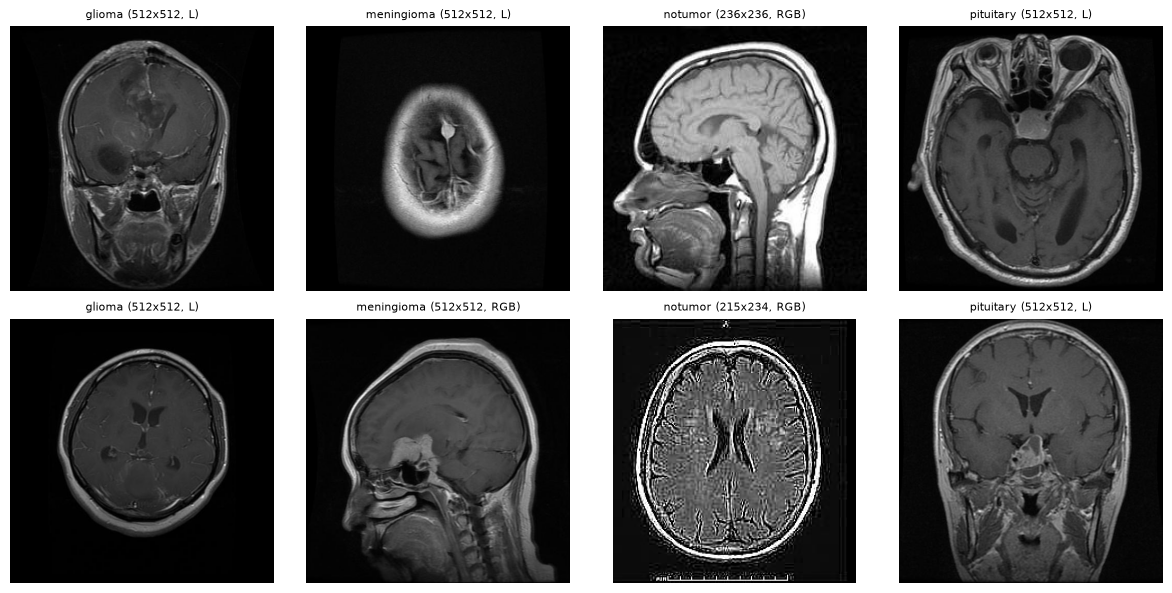

In [6]:
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, label in enumerate(classes):
    subset = df[(df["split"] == "Training") & (df["label"] == label)].sample(2, random_state=0)
    for row, path in enumerate(subset["path"]):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))  # conversion RGB pour l'affichage
        axes[row, col].set_title(f"{label} ({img.size[0]}x{img.size[1]}, {img.mode})", fontsize=8)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## Ce qu'on retient
- **Classes équilibrées** : exactement 1 400 images d'entraînement et 400 images de test par classe (5 600 + 1 600 = 7 200). L'accuracy est donc une métrique honnête (après le retrait des doublons dans `data.py`, les classes restent à peu près équilibrées).
- **Un seul format** : les 7 200 fichiers sont des JPEG.
- **Modes de couleur mélangés** : 3 067 images en niveaux de gris (`L`), 4 129 en `RGB`, 3 en `RGBA` et 1 en palette (`P`). Le modèle attend 3 canaux : chaque image doit être convertie en RGB au chargement (le chargeur par défaut de `ImageFolder` le fait).
- **Beaucoup de tailles** : 447 tailles distinctes, de 150 px à 1 446 px environ. 5 014 images font 512 x 512, mais certaines ne sont pas carrées. Tout redimensionner en 224 x 224 (entrée de ResNet-50) étire légèrement les images non carrées.
- **Suite** : chercher les images en double entre `Training` et `Testing` (`scripts/check_duplicates.py`), car des doublons feraient fuiter des données d'entraînement dans le score de test.